# Uczenie maszynowe 1
## Pracownia specjalistyczna nr 2
### Wstępne przetwarzanie danych: wartości brakujące i wartości odstające

Zbiór `pomiary_powietrza_dydaktyczne.csv` został przygotowany wyłącznie do celów dydaktycznych.

## Cele zajęć

Po wykonaniu ćwiczeń student powinien potrafić:
- rozpoznać różne sposoby zapisu brakujących wartości,
- ujednolicić kody braków do jednej reprezentacji,
- policzyć liczbę i udział braków w kolumnach,
- znaleźć rekordy zawierające wiele braków,
- zastosować prostą imputację cech numerycznych i jakościowych,
- dopasować imputer wyłącznie na części treningowej,
- rozpoznać wartości niemożliwe z punktu widzenia dziedziny,
- wykrywać potencjalne wartości odstające metodą IQR,
- policzyć klasyczny i zmodyfikowany Z-score,
- odróżnić błąd danych od rzadkiej, ale możliwej obserwacji.

## 1. Import bibliotek

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Część A. Wartości brakujące

## 2. Odczyt danych bez definiowania kodów braków

Na początku celowo wczytamy plik **bez** informowania pandas, że `-999`, `?` oraz napis `brak` oznaczają brak wartości. Dzięki temu zobaczymy, dlaczego samo `isna()` nie zawsze wystarcza.

In [56]:
raw = pd.read_csv("pomiary_powietrza_dydaktyczne.csv")
raw.head(10)

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3,pora_dnia
0,1,Centrum,4.8,78.0,7.2,42.0,rano
1,2,Północ,5.1,74.0,9.0,38.0,rano
2,3,Południe,6.3,70.0,5.5,34.0,rano
3,4,Centrum,7.8,68.0,6.0,39.0,południe
4,5,Północ,8.4,65.0,8.1,31.0,południe
5,6,Południe,-999.0,66.0,4.2,35.0,południe
6,7,Centrum,9.2,63.0,0.0,46.0,południe
7,8,Północ,8.9,62.0,brak,33.0,południe
8,9,Południe,7.7,72.0,3.8,41.0,wieczór
9,10,Centrum,6.9,76.0,5.1,52.0,wieczór


In [57]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              36 non-null     int64  
 1   stacja          36 non-null     str    
 2   temperatura_C   36 non-null     float64
 3   wilgotnosc_pct  35 non-null     float64
 4   wiatr_kmh       36 non-null     str    
 5   pm25_ug_m3      35 non-null     float64
 6   pora_dnia       36 non-null     str    
dtypes: float64(3), int64(1), str(3)
memory usage: 2.1 KB


### Co warto zauważyć?

Jeżeli w kolumnie liczbowej pojawi się tekst, np. `brak`, pandas może potraktować całą kolumnę jako tekstową (`object`). Kod `-999` zostanie natomiast odczytany jako zwykła liczba, jeżeli nie poinformujemy biblioteki, że ma oznaczać brak.

**Wniosek:** znaczenie kodów musi wynikać z opisu danych, a nie z samej wartości.

## 3. Ujednolicenie sposobu zapisu braków

W tym zbiorze przyjmujemy, że `-999`, `?`, `brak` oraz puste pole oznaczają brak. Wartość `0` nie jest automatycznie brakiem — np. `0 km/h` jest poprawnym pomiarem prędkości wiatru.

In [58]:
df = pd.read_csv(
    "pomiary_powietrza_dydaktyczne.csv",
    na_values=[-999, "?", "brak"]
)

df.head(10)

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3,pora_dnia
0,1,Centrum,4.8,78.0,7.2,42.0,rano
1,2,Północ,5.1,74.0,9.0,38.0,rano
2,3,Południe,6.3,70.0,5.5,34.0,rano
3,4,Centrum,7.8,68.0,6.0,39.0,południe
4,5,Północ,8.4,65.0,8.1,31.0,południe
5,6,Południe,NaN,66.0,4.2,35.0,południe
6,7,Centrum,9.2,63.0,0.0,46.0,południe
7,8,Północ,8.9,62.0,NaN,33.0,południe
8,9,Południe,7.7,72.0,3.8,41.0,wieczór
9,10,Centrum,6.9,76.0,5.1,52.0,wieczór


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              36 non-null     int64  
 1   stacja          35 non-null     str    
 2   temperatura_C   34 non-null     float64
 3   wilgotnosc_pct  35 non-null     float64
 4   wiatr_kmh       34 non-null     float64
 5   pm25_ug_m3      35 non-null     float64
 6   pora_dnia       36 non-null     str    
dtypes: float64(4), int64(1), str(2)
memory usage: 2.1 KB


## 4. Diagnozowanie braków

Sprawdzimy liczbę braków, procent braków oraz liczbę braków w poszczególnych wierszach.

In [60]:
missing_count = df.isna().sum()
missing_percent = 100 * df.isna().mean()

raport_brakow = pd.DataFrame({
    "liczba_brakow": missing_count,
    "procent_brakow": missing_percent.round(1)
})

raport_brakow

,liczba_brakow,procent_brakow
id,0,0.0
stacja,1,2.8
temperatura_C,2,5.6
wilgotnosc_pct,1,2.8
wiatr_kmh,2,5.6
pm25_ug_m3,1,2.8
pora_dnia,0,0.0


In [61]:
df["liczba_brakow_w_wierszu"] = df.isna().sum(axis=1)

df.loc[
    df["liczba_brakow_w_wierszu"] > 0,
    ["id", "stacja", "temperatura_C", "wilgotnosc_pct",
     "wiatr_kmh", "pm25_ug_m3", "liczba_brakow_w_wierszu"]
]

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3,liczba_brakow_w_wierszu
5,6,Południe,NaN,66.0,4.2,35.0,1
7,8,Północ,8.9,62.0,NaN,33.0,1
11,12,Południe,5.8,NaN,4.6,44.0,1
14,15,NaN,5.0,79.0,6.2,61.0,1
17,18,Południe,8.0,67.0,5.7,NaN,1
19,20,Północ,NaN,73.0,8.5,53.0,1
23,24,Południe,4.7,85.0,NaN,70.0,1


### Interpretacja

Sam procent braków nie rozstrzyga, co z nimi zrobić. Warto sprawdzić, **które cechy znikają razem** i czy braki występują częściej w określonych grupach danych.

## 5. Wzorce braków

In [62]:
cols = ["stacja", "temperatura_C", "wilgotnosc_pct", "wiatr_kmh", "pm25_ug_m3"]
patterns = df[cols].isna().value_counts()
patterns

stacja  temperatura_C  wilgotnosc_pct  wiatr_kmh  pm25_ug_m3
False   False          False           False      False         29
        True           False           False      False          2
        False          False           True       False          2
                       True            False      False          1
True    False          False           False      False          1
False   False          False           False      True           1
Name: count, dtype: int64

## 6. Usuwanie niekompletnych danych — dwa różne pytania

Porównajmy usunięcie wszystkich wierszy z jakimkolwiek brakiem z usunięciem tylko rekordów bez pomiaru PM2.5.

In [63]:
complete_rows = df.dropna()
known_pm25 = df.dropna(subset=["pm25_ug_m3"])

print("Liczba wszystkich rekordów:", len(df))
print("Po usunięciu wszystkich niekompletnych:", len(complete_rows))
print("Po pozostawieniu tylko znanych PM2.5:", len(known_pm25))

Liczba wszystkich rekordów: 36
Po usunięciu wszystkich niekompletnych: 29
Po pozostawieniu tylko znanych PM2.5: 35


`dropna()` może usunąć dużo informacji, nawet jeśli brak dotyczy cechy, która nie jest kluczowa dla analizowanego zadania.

## 7. Prosta imputacja cech numerycznych

Dopasujemy medianę wyłącznie na części treningowej, a następnie zastosujemy tę samą regułę do testu.

In [64]:
numeric_cols = ["temperatura_C", "wilgotnosc_pct", "wiatr_kmh", "pm25_ug_m3"]

X_train, X_test = train_test_split(
    df[numeric_cols], test_size=0.25, random_state=42
)

imputer_num = SimpleImputer(strategy="median")
X_train_imp = imputer_num.fit_transform(X_train)
X_test_imp = imputer_num.transform(X_test)

print("Mediany wyznaczone na treningu:")
for col, value in zip(numeric_cols, imputer_num.statistics_):
    print(f"{col}: {value}")

Mediany wyznaczone na treningu:
temperatura_C: 6.3
wilgotnosc_pct: 74.5
wiatr_kmh: 5.7
pm25_ug_m3: 55.0


### Dlaczego `fit()` wykonujemy tylko na treningu?

Gdybyśmy obliczyli mediany na całym zbiorze przed podziałem, informacja o rozkładzie części testowej wpłynęłaby na przygotowanie danych (data leakage).

## 8. Imputacja cechy jakościowej

Dla `stacja` porównamy najczęstszą kategorię z osobną kategorią `nieznana`.

In [65]:
cat = df[["stacja"]]

imp_mode = SimpleImputer(strategy="most_frequent")
imp_unknown = SimpleImputer(strategy="constant", fill_value="nieznana")

stacja_mode = imp_mode.fit_transform(cat).ravel()
stacja_unknown = imp_unknown.fit_transform(cat).ravel()

comparison = pd.DataFrame({
    "oryginal": df["stacja"],
    "moda": stacja_mode,
    "osobna_kategoria": stacja_unknown
})

comparison[df["stacja"].isna()]

,oryginal,moda,osobna_kategoria
14,NaN,Centrum,nieznana


## 9. Wskaźnik wystąpienia braku

Informacja o tym, że czegoś nie zmierzono, czasem sama może być użyteczna. `add_indicator=True` może dołączyć dodatkową zmienną 0/1.

In [66]:
imp_with_flag = SimpleImputer(strategy="median", add_indicator=True)

example = df[["temperatura_C", "wiatr_kmh"]].head(10)
filled_with_flag = imp_with_flag.fit_transform(example)

print("Kształt przed imputacją:", example.shape)
print("Kształt po imputacji i dodaniu wskaźników:", filled_with_flag.shape)
print(filled_with_flag)

Kształt przed imputacją: (10, 2)
Kształt po imputacji i dodaniu wskaźników: (10, 4)
[[4.8 7.2 0.  0. ]
 [5.1 9.  0.  0. ]
 [6.3 5.5 0.  0. ]
 [7.8 6.  0.  0. ]
 [8.4 8.1 0.  0. ]
 [7.7 4.2 1.  0. ]
 [9.2 0.  0.  0. ]
 [8.9 5.5 0.  1. ]
 [7.7 3.8 0.  0. ]
 [6.9 5.1 0.  0. ]]


# Część B. Wartości odstające

## 10. Najpierw kontrola dziedzinowa

W naszym dydaktycznym zbiorze przyjmujemy oczywiste reguły: wilgotność 0–100%, wiatr nieujemny, a temperatura 158°C jest błędem zapisu lub jednostki. Takie rekordy wymagają sprawdzenia u źródła.

In [67]:
domain_problem = (
    (df["wilgotnosc_pct"] < 0) |
    (df["wilgotnosc_pct"] > 100) |
    (df["wiatr_kmh"] < 0) |
    (df["temperatura_C"] > 60)
)

df.loc[
    domain_problem,
    ["id", "stacja", "temperatura_C", "wilgotnosc_pct", "wiatr_kmh", "pm25_ug_m3"]
]

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3
10,11,Północ,6.5,145.0,6.7,49.0
21,22,Centrum,5.9,81.0,-4.0,66.0
28,29,Północ,158.0,72.0,7.0,64.0


**Odstająca wartość nie oznacza automatycznie błędu.** Bardzo wysokie PM2.5 może być rzadkim, ale rzeczywistym epizodem. Z kolei wilgotność 145% jest niezgodna z definicją cechy.

## 11. Potwierdzone błędy zamieniamy na braki

Załóżmy, że nie możemy odzyskać poprawnych wartości dla oczywistych błędnych pomiarów.

In [68]:
df_clean = df.copy()

df_clean.loc[(df_clean["wilgotnosc_pct"] < 0) | (df_clean["wilgotnosc_pct"] > 100), "wilgotnosc_pct"] = np.nan
df_clean.loc[df_clean["wiatr_kmh"] < 0, "wiatr_kmh"] = np.nan
df_clean.loc[df_clean["temperatura_C"] > 60, "temperatura_C"] = np.nan

df_clean.isna().sum()

id                         0
stacja                     1
temperatura_C              3
wilgotnosc_pct             2
wiatr_kmh                  3
pm25_ug_m3                 1
pora_dnia                  0
liczba_brakow_w_wierszu    0
dtype: int64

## 12. Wizualna analiza rozkładu PM2.5

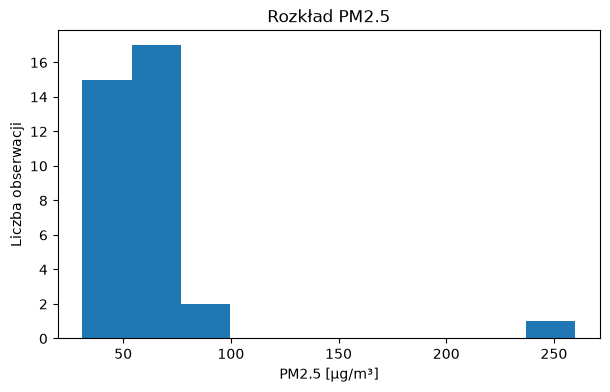

In [69]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["pm25_ug_m3"].dropna(), bins=10)
plt.xlabel("PM2.5 [µg/m³]")
plt.ylabel("Liczba obserwacji")
plt.title("Rozkład PM2.5")
plt.show()

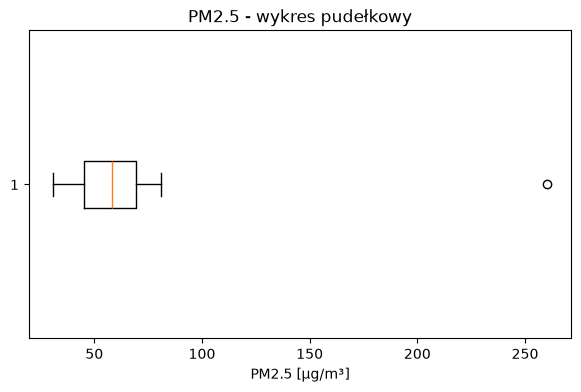

In [70]:
plt.figure(figsize=(7, 4))
plt.boxplot(df_clean["pm25_ug_m3"].dropna(), orientation='horizontal')
plt.xlabel("PM2.5 [µg/m³]")
plt.title("PM2.5 - wykres pudełkowy")
plt.show()

## 13. Reguła IQR

Obliczamy:

\[
IQR = Q_3 - Q_1
\]

a następnie granice:

\[
L = Q_1 - 1.5IQR
\]

\[
U = Q_3 + 1.5IQR
\]

Wartości poza zakresem traktujemy jako **kandydatów do sprawdzenia**, a nie automatyczne błędy.

In [71]:
pm = df_clean["pm25_ug_m3"].dropna()

q1 = pm.quantile(0.25)
q3 = pm.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Dolna granica:", low)
print("Górna granica:", high)

iqr_outliers = df_clean[(df_clean["pm25_ug_m3"] < low) | (df_clean["pm25_ug_m3"] > high)]
iqr_outliers[["id", "stacja", "pm25_ug_m3", "pora_dnia"]]

Q1: 45.0
Q3: 69.5
IQR: 24.5
Dolna granica: 8.25
Górna granica: 106.25


,id,stacja,pm25_ug_m3,pora_dnia
26,27,Południe,260.0,rano


Reguła statystyczna wskazuje obserwację do analizy — nie podaje przyczyny.

## 14. Z-score

Klasyczny Z-score mierzy odległość od średniej w jednostkach odchylenia standardowego. Próg `|z| > 3` jest regułą pomocniczą.

In [72]:
pm_mean = pm.mean()
pm_std = pm.std(ddof=1)
z = (pm - pm_mean) / pm_std
z_outliers = pm[z.abs() > 3]

print("Średnia:", round(pm_mean, 2))
print("Odchylenie standardowe:", round(pm_std, 2))
print("Wartości z |z| > 3:")
print(z_outliers)

Średnia: 62.03
Odchylenie standardowe: 37.3
Wartości z |z| > 3:
26    260.0
Name: pm25_ug_m3, dtype: float64


## 15. Zmodyfikowany Z-score oparty na MAD

MAD jest oparty na medianie i słabiej reaguje na pojedyncze skrajności.

\[
MAD = median(|x_i - \tilde{x}|)
\]

\[
M_i = \frac{0.6745(x_i - \tilde{x})}{MAD}
\]

Często stosuje się próg `|M| > 3.5`.

In [73]:
pm_median = pm.median()
mad = (pm - pm_median).abs().median()

if mad > 0:
    modified_z = 0.6745 * (pm - pm_median) / mad
    mad_outliers = pm[modified_z.abs() > 3.5]
else:
    modified_z = pd.Series(np.nan, index=pm.index)
    mad_outliers = pd.Series(dtype=float)

print("Mediana:", pm_median)
print("MAD:", mad)
print("Wartości oznaczone przez zmodyfikowany Z-score:")
print(mad_outliers)

Mediana: 58.0
MAD: 12.0
Wartości oznaczone przez zmodyfikowany Z-score:
26    260.0
Name: pm25_ug_m3, dtype: float64


## 16. Porównanie IQR, Z-score i MAD

In [74]:
comparison_outliers = pd.DataFrame({
    "pm25": pm,
    "IQR": (pm < low) | (pm > high),
    "Z_score": z.abs() > 3,
    "MAD": modified_z.abs() > 3.5
})

comparison_outliers[comparison_outliers[["IQR", "Z_score", "MAD"]].any(axis=1)]

,pm25,IQR,Z_score,MAD
26,260.0,True,True,True


## 17. Co zrobić z wartością odstającą?

Nie istnieje jedna automatyczna operacja odpowiednia dla każdego przypadku.

1. **Potwierdzony błąd** — poprawić u źródła; jeśli nie znamy poprawnej wartości, oznaczyć jako brak.
2. **Rzadka, ale poprawna obserwacja** — zwykle zachować i sprawdzić jej wpływ na model.
3. **Wartość skrajna silnie wpływająca na analizę** — porównać warianty z transformacją, metodą odporną albo ograniczeniem wartości.
4. **Usunięcie rekordu** — wymaga uzasadnienia, bo zmienia badaną próbę.

Poniższy kod pokazuje tylko techniczny przykład ograniczenia PM2.5 do granic IQR. Nie oznacza to, że jest to właściwa decyzja dla tego zbioru.

In [75]:
df_clip = df_clean.copy()
df_clip["pm25_po_ograniczeniu"] = df_clip["pm25_ug_m3"].clip(lower=low, upper=high)

df_clip.loc[
    df_clip["pm25_ug_m3"] != df_clip["pm25_po_ograniczeniu"],
    ["id", "pm25_ug_m3", "pm25_po_ograniczeniu"]
]

,id,pm25_ug_m3,pm25_po_ograniczeniu
17,18,NaN,NaN
26,27,260.0,106.25


## 18. Jak zmieniają się statystyki po ograniczeniu wartości?

In [76]:
before = df_clean["pm25_ug_m3"].describe()
after = df_clip["pm25_po_ograniczeniu"].describe()

pd.DataFrame({"przed": before, "po_ograniczeniu": after})

,przed,po_ograniczeniu
count,35.000000,35.000000
mean,62.028571,57.635714
std,37.295707,16.610077
min,31.000000,31.000000
25%,45.000000,45.000000
50%,58.000000,58.000000
75%,69.500000,69.500000
max,260.000000,106.250000


# Część C. Zadania do samodzielnego wykonania

## Zadanie 1. Raport brakujących wartości

Wczytaj ponownie plik, przyjmując, że `-999`, `?` i `brak` oznaczają wartości brakujące. Utwórz tabelę zawierającą liczbę i procent braków dla każdej kolumny. Posortuj malejąco według procentu braków.

In [77]:
# TODO - Zadanie 1
df = pd.read_csv(
    "pomiary_powietrza_dydaktyczne.csv",
    na_values=[-999, "?", "brak"]
)

missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_table = pd.DataFrame({
    "liczba_brakow": missing_count,
    "procent_brakow": missing_percent.round(1)
})

missing_table

,liczba_brakow,procent_brakow
id,0,0.0
stacja,1,2.8
temperatura_C,2,5.6
wilgotnosc_pct,1,2.8
wiatr_kmh,2,5.6
pm25_ug_m3,1,2.8
pora_dnia,0,0.0


## Zadanie 2. Rekordy z wieloma brakami

Znajdź wszystkie wiersze, w których występują **co najmniej dwa braki**. Wyświetl `id`, wszystkie cechy i liczbę braków w danym wierszu.

In [87]:
# TODO - Zadanie 2
df["liczba_brakow_w_wierszu"] = df.isna().sum(axis=1)

df.loc[
    df["liczba_brakow_w_wierszu"] > 1,
    df.columns
]

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3,pora_dnia,liczba_brakow_w_wierszu


## Zadanie 3. Imputacja numeryczna

Podziel dane numeryczne na trening i test w proporcji 70/30 (`random_state=7`). Następnie dopasuj `SimpleImputer(strategy="median")` tylko na treningu, przekształć trening i test, wyświetl statystyki i sprawdź, czy po transformacji pozostały braki. Sprawdź działanie i wyniki otrzymane innymi metodami, np: średnia, kNN.

In [94]:
# TODO - Zadanie 3

numeric_cols = ["temperatura_C", "wilgotnosc_pct", "wiatr_kmh", "pm25_ug_m3"]

X_train, X_test = train_test_split(
    df[numeric_cols], train_size=0.3, random_state=7
)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

for col, val in zip(numeric_cols, imputer.statistics_):
    print(f"{col}: {val}")

X_train_imp

temperatura_C: 5.4
wilgotnosc_pct: 76.0
wiatr_kmh: 6.300000000000001
pm25_ug_m3: 62.5


array([[  5.4,  79. ,   6.1,  68. ],
       [  5. ,  79. ,   6.2,  61. ],
       [  4.5,  81. ,   6.4,  76. ],
       [158. ,  72. ,   7. ,  64. ],
       [  8.9,  62. ,   6.3,  33. ],
       [  4.7,  85. ,   6.3,  70. ],
       [  5.4,  73. ,   8.5,  53. ],
       [  7.8,  68. ,   6. ,  39. ],
       [  3.3,  86. ,   5. ,  74. ],
       [  8.4,  65. ,   8.1,  31. ]])

## Zadanie 4. Dwie strategie dla kategorii

Dla kolumny `stacja` porównaj imputację najczęstszą kategorią z imputacją stałą wartością `brak_stacji`. Wyświetl tylko rekordy, w których pierwotnie brakowało stacji.

**Pytanie:** czym różni się znaczenie tych dwóch strategii?

In [106]:
# TODO - Zadanie 4
station = df[["stacja"]]

imp_moda = SimpleImputer(strategy="most_frequent")
imp_constant = SimpleImputer(strategy="constant", fill_value="brak_stacji")

# ravel() spłaszcza tablice dwuwymiarową w jednowymiarową (numpy)
station_moda = imp_moda.fit_transform(station).ravel()
station_constant = imp_constant.fit_transform(station).ravel()

comparison = pd.DataFrame({
    "original": df["stacja"],
    "moda": station_moda,
    "constant": station_constant
})

comparison[df["stacja"].isna()]

,original,moda,constant
14,NaN,Centrum,brak_stacji


## Zadanie 5. Kontrola dziedzinowa

Przyjmij reguły: wilgotność 0–100%, wiatr ≥ 0 km/h, temperatura od -40°C do 50°C. Znajdź wszystkie rekordy naruszające co najmniej jedną regułę. Nie usuwaj ich automatycznie.

In [111]:
# TODO - Zadanie 5
rules = (
    (df["wilgotnosc_pct"] < 0) |
    (df["wilgotnosc_pct"] > 100) |
    (df["wiatr_kmh"] < 0) |
    (df["temperatura_C"] < -40) |
    (df["temperatura_C"] > 50)
)

df.loc[
    rules,
    df.columns
]

,id,stacja,temperatura_C,wilgotnosc_pct,wiatr_kmh,pm25_ug_m3,pora_dnia,liczba_brakow_w_wierszu
10,11,Północ,6.5,145.0,6.7,49.0,wieczór,0
21,22,Centrum,5.9,81.0,-4.0,66.0,wieczór,0
28,29,Północ,158.0,72.0,7.0,64.0,południe,0


## Zadanie 6. IQR dla prędkości wiatru

Po zamianie wartości niemożliwych na `NaN`: oblicz Q1, Q3 i IQR dla `wiatr_kmh`, wyznacz granice 1.5 × IQR, wypisz rekordy poza granicami i narysuj wykres pudełkowy.

Q1: 4.6
Q3: 7.0
IQR: 2.4000000000000004
Dolna granica: 0.9999999999999991
Górna granica: 10.600000000000001
   id   stacja  wiatr_kmh
6   7  Centrum        0.0


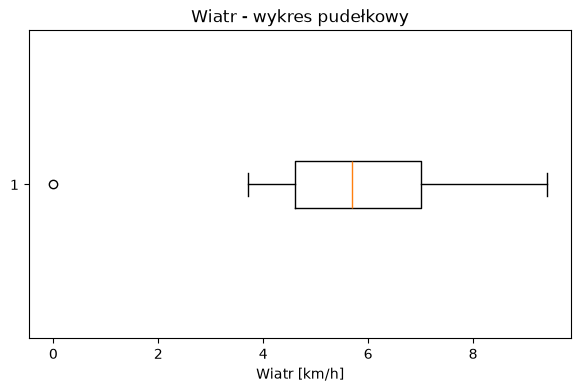

In [119]:
# TODO - Zadanie 6
df_clean = df.copy()

df_clean.loc[(df_clean["wilgotnosc_pct"] < 0) | (df_clean["wilgotnosc_pct"] > 100), "wilgotnosc_pct"] = np.nan
df_clean.loc[df_clean["wiatr_kmh"] < 0, "wiatr_kmh"] = np.nan
df_clean.loc[(df_clean["temperatura_C"] < -40) | (df_clean["temperatura_C"] > 60), "temperatura_C"] = np.nan

wiatr = df_clean["wiatr_kmh"]

q1 = wiatr.quantile(0.25)
q3 = wiatr.quantile(0.75)

iqr = q3 - q1

low = q1 - 1.5*iqr
high = q3 + 1.5*iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Dolna granica:", low)
print("Górna granica:", high)

iqr_outliers = df_clean[(df_clean["wiatr_kmh"] < low) | (df_clean["wiatr_kmh"] > high)]
print(iqr_outliers[["id", "stacja", "wiatr_kmh"]])

plt.figure(figsize=(7, 4))
plt.boxplot(df_clean["wiatr_kmh"].dropna(), orientation='horizontal')
plt.xlabel("Wiatr [km/h]")
plt.title("Wiatr - wykres pudełkowy")
plt.show()

## Zadanie 7. Porównanie metod dla PM2.5

Dla `pm25_ug_m3` zastosuj regułę IQR, klasyczny Z-score z progiem 3 i zmodyfikowany Z-score z progiem 3.5. Utwórz jedną tabelę pokazującą, które obserwacje oznaczyła każda metoda.

In [127]:
# TODO - Zadanie 7
# IQR
pm = df_clean["pm25_ug_m3"]

q1 = pm.quantile(0.25)
q3 = pm.quantile(0.75)

iqr = q3 - q1

low = q1 - 1.5*iqr
high = q3 + 1.5*iqr
iqr_outliers = pm[(pm < low) | (pm > high)]

# Z-score
pm_mean = pm.mean()
pm_std = pm.std(ddof=1)
z = (pm - pm_mean) / pm_std
z_outliers = pm[z.abs() > 3]

# Zmodyfikowany Z-score
pm_median = pm.median()
mad = (pm - pm_median).abs().median()

if mad > 0:
    modified_z = 0.6745 * (pm - pm_median) / mad
    mad_outliers = pm[modified_z.abs() > 3.5]
else:
    modified_z = pd.Series(np.nan, index=pm.index)
    mad_outliers = pd.Series(dtype=float)

# Porównanie
comparison_outliers = pd.DataFrame({
    "pm25": pm,
    "IQR": iqr_outliers,
    "Z_score": z_outliers,
    "MAD": mad_outliers
})

comparison_outliers[comparison_outliers[["IQR", "Z_score", "MAD"]].any(axis=1)]


,pm25,IQR,Z_score,MAD
26,260.0,260.0,260.0,260.0


## Zadanie 8. Wpływ obserwacji skrajnej

Policz średnią, medianę i odchylenie standardowe PM2.5 najpierw dla wszystkich dostępnych wartości, a potem po usunięciu największej wartości.

**Które statystyki zmieniły się najbardziej i dlaczego?**

In [138]:
# TODO - Zadanie 8
print(f"Średnia: {pm.mean()}")
print(f"Mediana: {pm.median()}")
print(f"Odchylenie: {pm.std()}")

pm = pm.drop(pm.idxmax())

print(f"Średnia: {pm.mean()}")
print(f"Mediana: {pm.median()}")
print(f"Odchylenie: {pm.std()}")

Średnia: 62.02857142857143
Mediana: 58.0
Odchylenie: 37.295706829327685
Średnia: 56.205882352941174
Mediana: 57.5
Odchylenie: 14.509723827885123


## Zadanie 9. Decyzja analityczna

Dla każdego przypadku zaproponuj działanie i je uzasadnij:

1. wilgotność = 145%,
2. wiatr = -4 km/h,
3. PM2.5 = 260 µg/m³,
4. brak nazwy stacji.

Możliwe decyzje: poprawienie po sprawdzeniu źródła, zamiana na brak, imputacja, pozostawienie, wskaźnik braku, usunięcie rekordu.

### Twoja odpowiedź
1. poprawienie po sprawdzeniu źródła
2. poprawienie po sprawdzeniu źródła
3. pozostawienie
4. usunięcie rekordu

## Zadanie dodatkowe

Użyj `SimpleImputer(strategy="median", add_indicator=True)` dla dwóch wybranych cech numerycznych. Sprawdź liczbę kolumn przed i po transformacji oraz wskaż, które nowe kolumny reprezentują informację o brakach.

In [140]:
# TODO - Zadanie dodatkowe
imp = SimpleImputer(strategy="median", add_indicator=True)

example = df[["temperatura_C", "wiatr_kmh"]]

filled_with_flag = imp_with_flag.fit_transform(example)

print("Kształt przed imputacją:", example.shape)
print("Kształt po imputacji i dodaniu wskaźników:", filled_with_flag.shape)
print(filled_with_flag)


Kształt przed imputacją: (36, 2)
Kształt po imputacji i dodaniu wskaźników: (36, 4)
[[  4.8    7.2    0.     0.  ]
 [  5.1    9.     0.     0.  ]
 [  6.3    5.5    0.     0.  ]
 [  7.8    6.     0.     0.  ]
 [  8.4    8.1    0.     0.  ]
 [  6.     4.2    1.     0.  ]
 [  9.2    0.     0.     0.  ]
 [  8.9    5.65   0.     1.  ]
 [  7.7    3.8    0.     0.  ]
 [  6.9    5.1    0.     0.  ]
 [  6.5    6.7    0.     0.  ]
 [  5.8    4.6    0.     0.  ]
 [  3.9    7.8    0.     0.  ]
 [  4.2    9.4    0.     0.  ]
 [  5.     6.2    0.     0.  ]
 [  7.     4.9    0.     0.  ]
 [  7.5    7.1    0.     0.  ]
 [  8.     5.7    0.     0.  ]
 [  8.8    6.4    0.     0.  ]
 [  6.     8.5    1.     0.  ]
 [  6.7    4.4    0.     0.  ]
 [  5.9   -4.     0.     0.  ]
 [  5.5    7.3    0.     0.  ]
 [  4.7    5.65   0.     1.  ]
 [  2.8    3.9    0.     0.  ]
 [  3.3    5.     0.     0.  ]
 [  3.7    4.1    0.     0.  ]
 [  6.1    6.8    0.     0.  ]
 [158.     7.     0.     0.  ]
 [  7.2    5.2   

# Literatura i materiały

- **Han, Kamber, Pei**, *Data Mining: Concepts and Techniques*, wyd. 3, Morgan Kaufmann, 2012.
- **Tan, Steinbach, Karpatne, Kumar**, *Introduction to Data Mining*, wyd. 2, Pearson, 2019.
- **S. van Buuren**, *Flexible Imputation of Missing Data*, wyd. 2, CRC Press, 2018.